# Part A - Data Quality & Basic Insights

This section checks the original sales file, cleans rows that cannot be used reliably, explores revenue, and saves a cleaned copy. The original `sales_raw.csv` stays unchanged.

In [36]:
# I will use pandas for the tables and matplotlib for the charts.
import pandas as pd
import matplotlib.pyplot as plt

In [37]:
# Load the original file and take a first look at its contents.
sales_raw_df=pd.read_csv("sales_raw.csv")

# These checks show the first rows, table size, field names, and data types.

print(sales_raw_df.head())

print(sales_raw_df.shape)

print(sales_raw_df.columns)

print(sales_raw_df.dtypes)



# Check which fields have missing values and whether any full rows are repeated.

print("Total missing values in each column \n ",sales_raw_df.isna().sum())
print("Total duplicated values in our dataset \n ",sales_raw_df.duplicated().sum())

   transaction_id  sale_date region    category  quantity unit_price
0            1001  10/1/2026  North       food        2.0        120
1            1002  10/1/2026  South       Books       1.0        250
2            1003  10/2/2026  North        Food       3.0        110
3            1004  10/2/2026   East  Stationery       4.0         50
(21, 6)
Index(['transaction_id', 'sale_date', 'region', 'category', 'quantity',
       'unit_price'],
      dtype='str')
transaction_id      int64
sale_date             str
region                str
category              str
quantity          float64
unit_price            str
dtype: object
Total missing values in each column 
  transaction_id    0
sale_date         0
region            1
category          0
quantity          1
unit_price        1
dtype: int64
Total duplicated values in our dataset 
  1


In [38]:
# Clean a copy so the original rows in sales_raw_df remain untouched.
# Strip extra spaces and use title case so labels such as food/Food match.

clean_data_df=sales_raw_df.copy()

clean_data_df["category"]=clean_data_df["category"].str.strip().str.title()
clean_data_df["region"]=clean_data_df["region"].str.strip().str.title()


print(clean_data_df["region"].unique())
print(clean_data_df["category"].unique())

# Parse dates and prices into usable types. Unreadable values become missing for review.
clean_data_df["sale_date"]=pd.to_datetime(clean_data_df["sale_date"],errors="coerce")
clean_data_df["unit_price"]=pd.to_numeric(clean_data_df["unit_price"],errors="coerce")

# Look at affected rows before deciding how to handle them.

print(clean_data_df.loc[clean_data_df.isna().any(axis=1)])


# Keep rows with an unknown region and label that region as Unknown.
# I will drop rows with missing/invalid quantity or price instead of guessing values,
# since either guess would change the calculated revenue. An unparseable date is
# also dropped because it cannot be used as a valid sale date.


clean_data_df["region"]=clean_data_df["region"].fillna("Unknown")

# Remove rows where quantity is missing or not positive.

clean_data_df=clean_data_df.loc[clean_data_df["quantity"] > 0]


print(clean_data_df.isna().sum())


# Remove rows where price is missing/invalid or not positive.

clean_data_df=clean_data_df.loc[clean_data_df["unit_price"] > 0]


print(clean_data_df.isna().sum())


# Remove rows whose date could not be parsed.

clean_data_df=clean_data_df.loc[~(clean_data_df["sale_date"].isna())]

print(clean_data_df.isna().sum())


# Remove exact duplicate rows so they are not counted twice.

clean_data_df=clean_data_df.drop_duplicates()



# Compare the original and cleaned row counts.


print("Before Cleaning ",sales_raw_df.shape)
print("After Cleaning ",clean_data_df.shape)




<ArrowStringArray>
['North', 'South', 'East', 'West', nan]
Length: 5, dtype: str
<ArrowStringArray>
['Food', 'Books', 'Stationery']
Length: 3, dtype: str
    transaction_id  sale_date region    category  quantity  unit_price
5             1006 2026-10-03   West        Food       NaN       130.0
9             1010 2026-10-05  South  Stationery       2.0         NaN
10            1011 2026-10-06   East        Food       2.0         NaN
13            1014        NaT   West       Books       2.0       300.0
17            1018 2026-10-09    NaN       Books       2.0       200.0
transaction_id    0
sale_date         1
region            0
category          0
quantity          0
unit_price        2
dtype: int64
transaction_id    0
sale_date         1
region            0
category          0
quantity          0
unit_price        0
dtype: int64
transaction_id    0
sale_date         0
region            0
category          0
quantity          0
unit_price        0
dtype: int64
Before Cleaning  (21,

In [39]:
# Calculate revenue for each sale, then compare totals across regions and categories.

clean_data_df["revenue"]=clean_data_df["quantity"] * clean_data_df["unit_price"]


# Summarizing revenue by region and category

revenue_by_region=clean_data_df.groupby("region")["revenue"].sum()

print(revenue_by_region)


revenue_by_category=clean_data_df.groupby("category")["revenue"].sum()

print(revenue_by_category)

region
East         740.0
North      11470.0
South       1035.0
Unknown      400.0
West         530.0
Name: revenue, dtype: float64
category
Books          1770.0
Food           1945.0
Stationery    10460.0
Name: revenue, dtype: float64


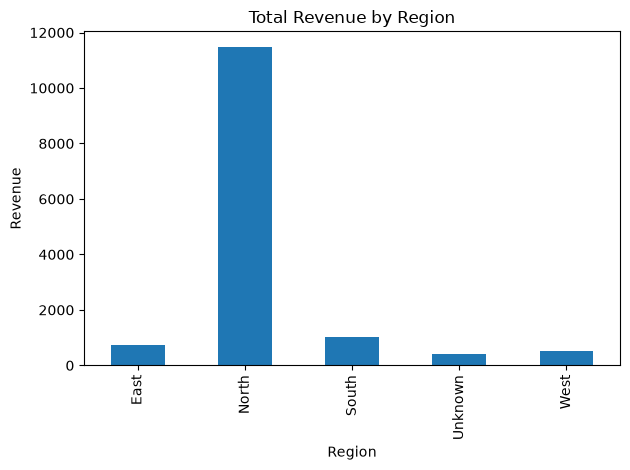

In [40]:
# Chart 1: compare total revenue across regions.
revenue_by_region.plot(kind="bar")
plt.title("Total Revenue by Region")
plt.xlabel("Region")
plt.ylabel("Revenue")
plt.tight_layout()
plt.show()

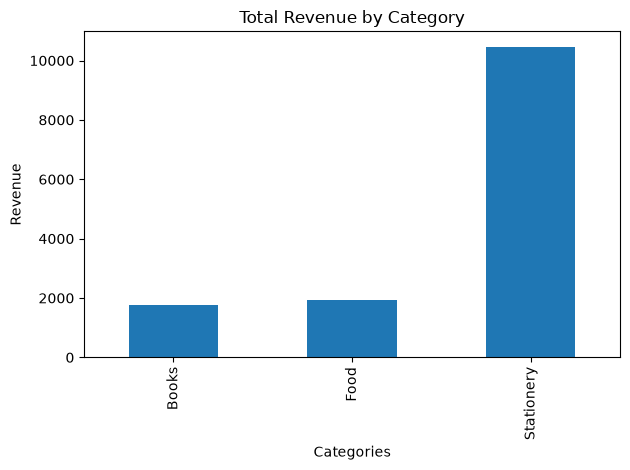

In [41]:
# Chart 2: compare total revenue across categories.
revenue_by_category.plot(kind="bar")
plt.title("Total Revenue by Category")
plt.xlabel("Category")
plt.ylabel("Revenue")
plt.tight_layout()
plt.show()

In [42]:
# Save the cleaned data as a separate file; the raw input remains unchanged.
clean_data_df.to_csv("cleaned_sales.csv", index=False)

## Findings

- **North had the highest regional revenue** at 11,470, compared with 400 for Unknown, the lowest total.
- **Stationery had the highest category revenue** at 10,460, while Books had the lowest at 1,770.